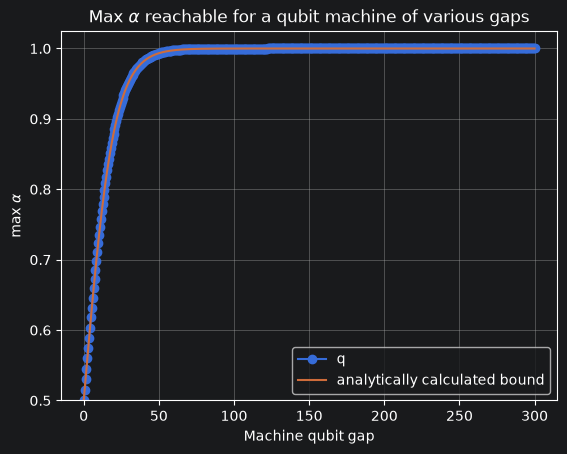

In [24]:
import matplotlib.pyplot as plt
from polytope_cooling.systems import SingleSystem, CombinedSystem
import numpy as np

energies = []
model = []
temp = 10
for gap in np.linspace(0.0001, 300, 500):
    system = SingleSystem.maximally_mixed([0, 1])
    machine = SingleSystem.thermal_system_from_temperature_and_gaps([gap], temp=temp)
    combined = CombinedSystem.from_systems(system, machine)
    a_min = combined.min_alpha()
    steps = list(a_min.construct_path())
    step_data = [(gap, step.alpha) for step in steps]
    energies.append(step_data[-1])
    model.append((gap, 1 / (1 + np.exp(-1 / temp * gap))))

alpha_values, e_values = zip(*energies)
plt.plot(alpha_values, e_values, marker='o', label="q")
alpha_values, e_values = zip(*model)
plt.plot(alpha_values, e_values, marker='', label="analytically calculated bound")
plt.ylabel(r"max $\alpha$")
plt.xlabel(r"Machine qubit gap")
plt.title(r'Max $\alpha$ reachable for a qubit machine of various gaps')
plt.legend()
ax = plt.gca()
ax.set_ylim((0.5, ax.get_ylim()[1]))
plt.grid(True)
plt.show()

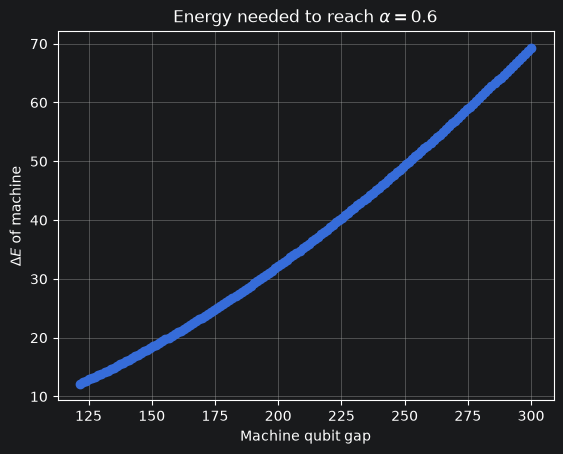

In [2]:
import matplotlib.pyplot as plt
from polytope_cooling.systems import SingleSystem, CombinedSystem
import numpy as np

alpha_goal = 0.6

energies = []
for gap in np.linspace(0, 300, 250):
    system = SingleSystem.maximally_mixed([0, 1])
    machine = SingleSystem.thermal_system_from_temperature_and_gaps([gap])
    combined = CombinedSystem.from_systems(system, machine)
    a_min = combined.min_alpha()
    steps = list(a_min.construct_path())
    step_data = [(step.alpha, step.trace_out_system().energy - combined.trace_out_system().energy) for step in steps]
    if step_data[-1][0] < alpha_goal:
        continue
    energies.append((gap, np.interp(alpha_goal, step_data[-2], step_data[-1])))

alpha_values, e_values = zip(*energies)
plt.plot(alpha_values, e_values, marker='o')
plt.xlabel(r"Machine qubit gap")
plt.ylabel(r"$\Delta E$ of machine")
plt.title(rf'Energy needed to reach $\alpha={alpha_goal}$')
ax = plt.gca()
#ax.set_ylim((0, ax.get_ylim()[1]))
plt.grid(True)
plt.show()

In [29]:
import matplotlib.pyplot as plt
from polytope_cooling.systems import SingleSystem, CombinedSystem
import numpy as np
from tqdm import tqdm

best_energies = []

for alpha in tqdm(np.linspace(0.501, 0.7, 50)):
    energies = []
    for gap in np.linspace(0, 300, 500):
        system = SingleSystem.maximally_mixed([0, 1])
        machine = SingleSystem.thermal_system_from_temperature_and_gaps([gap])
        combined = CombinedSystem.from_systems(system, machine)
        a_min = combined.min_alpha()
        steps = list(a_min.construct_path())
        step_data = [(step.alpha, step.trace_out_system().energy - combined.trace_out_system().energy) for step in steps]
        if step_data[-1][0] < alpha:
            continue
        energies.append((gap, np.interp(alpha_goal, step_data[-2], step_data[-1])))

    gap_values, e_values = zip(*energies)
    best = np.argmin(e_values)
    best_energies.append((alpha, gap_values[best], e_values[best]))

100%|██████████| 50/50 [00:04<00:00, 10.13it/s]


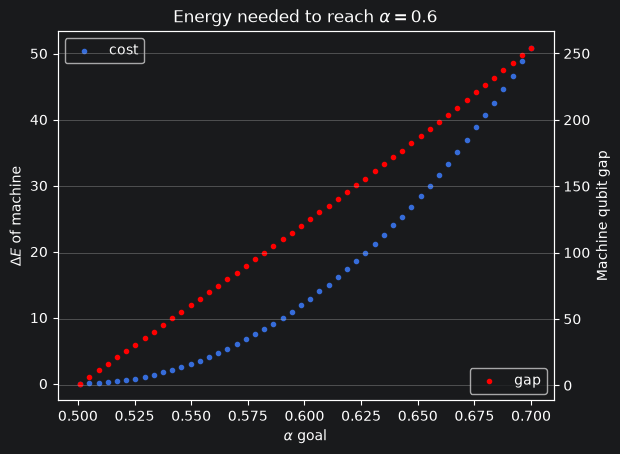

In [31]:
alpha_values, gap_values, e_values = zip(*best_energies)
ax = plt.gca()
ax.scatter(alpha_values, e_values, marker='.', label="cost")
ax2 = ax.twinx()
ax2.scatter(alpha_values, gap_values, marker='.', label="gap", color="red")
ax2.set_ylabel(r"Machine qubit gap")
ax.set_ylabel(r"$\Delta E$ of machine")
ax.set_xlabel(r"$\alpha$ goal")
plt.title(rf'Energy needed to reach $\alpha={alpha_goal}$')
#ax.set_ylim((0, ax.get_ylim()[1]))
ax.legend()
ax2.legend(loc="lower right")
plt.grid(True)
plt.show()